In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [2]:
train_data = pd.read_csv("mnist_train.csv")
test_data = pd.read_csv("mnist_test.csv")

print("Training Shape:", train_data.shape)
print("Testing Shape:", test_data.shape)

Training Shape: (60000, 785)
Testing Shape: (10000, 785)


In [17]:
# Separate Features and Labels

In [3]:
X_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

X_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

In [ ]:
# Normalize Pixel Values

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [ ]:
# Reshape Images

In [5]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("New Training Shape:", X_train.shape)

New Training Shape: (60000, 28, 28, 1)


In [ ]:
# build CNN model

In [6]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),

    MaxPooling2D(pool_size=(2,2)),

    Conv2D(64, (3,3), activation='relu'),

    MaxPooling2D(pool_size=(2,2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Compile Model

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# Display model Summary

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Train CNN model

In [10]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 80ms/step - accuracy: 0.9353 - loss: 0.2258 - val_accuracy: 0.9830 - val_loss: 0.0590
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 33s 77ms/step - accuracy: 0.9815 - loss: 0.0581 - val_accuracy: 0.9877 - val_loss: 0.0454
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 30s 71ms/step - accuracy: 0.9876 - loss: 0.0403 - val_accuracy: 0.9885 - val_loss: 0.0376
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 73ms/step - accuracy: 0.9901 - loss: 0.0320 - val_accuracy: 0.9892 - val_loss: 0.0407
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 86ms/step - accuracy: 0.9928 - loss: 0.0237 - val_accuracy: 0.9907 - val_loss: 0.0339
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 31s 73ms/step - accuracy: 0.9934 - loss: 0.0206 - val_accuracy: 0.9910 - val_loss: 0.0312
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 30s 71ms/step - accuracy: 0.9944 - loss: 0.0163 - val_accuracy: 0.9905 - val_loss: 0.0319
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 30s 70ms/step - accuracy: 0.9960 - loss: 0.0118 - 

In [11]:
# Evaluate Testing Accuracy

In [12]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Testing Loss:", test_loss)
print("Testing Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9900 - loss: 0.0358
Testing Loss: 0.03581129387021065
Testing Accuracy: 99.00000095367432 %


In [13]:
# Plot Training and Validation Accuracy

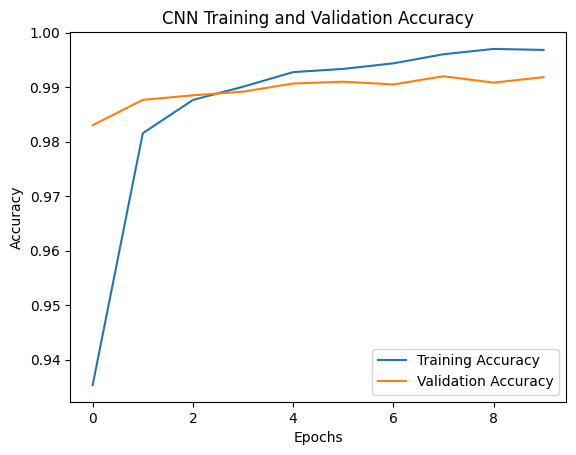

In [14]:
plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('CNN Training and Validation Accuracy')
plt.legend()
plt.show()

In [15]:
# Plot Training and Validation Loss

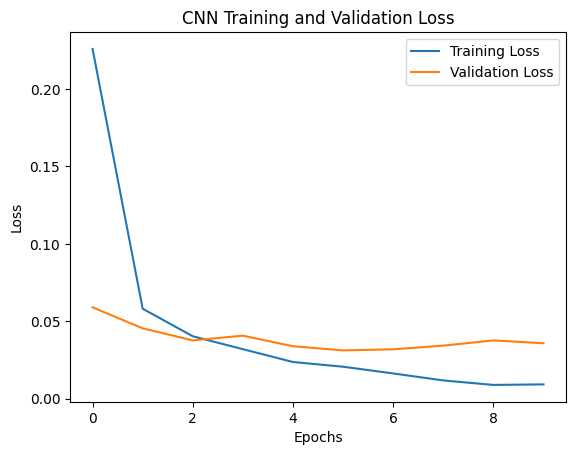

In [16]:
plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('CNN Training and Validation Loss')
plt.legend()
plt.show()

Here are **25 important code-based viva questions with answers** covering both Practical 17 and Practical 20 – CNN using Handwritten MNIST.

## CNN – Handwritten MNIST: 25 Viva Questions

**1. What is CNN?**  
CNN stands for Convolutional Neural Network. It is a deep learning model mainly used for image recognition and classification.

**2. Which function is used to load the MNIST dataset?**  
`mnist.load_data()` – It loads handwritten digit images.

**3. How many training and testing images are present in MNIST?**  
60,000 training images and 10,000 testing images.

**4. What is the size of each MNIST image?**  
28 × 28 pixels.

**5. Why do we divide pixel values by 255?**  
To normalize pixel values from 0–255 to 0–1.

**6. Why do we use `reshape(-1, 28, 28, 1)`?**  
To reshape images into the format required by CNN: height, width and channels. Here, 1 represents grayscale.

**7. What is the purpose of `Sequential()`?**  
It creates a neural network by adding layers one after another.

**8. What is `Conv2D()`?**  
It is a convolutional layer that extracts features such as edges, shapes and patterns from images.

**9. What does `Conv2D(32, (3,3), activation='relu')` mean?**  
It creates 32 filters, each of size 3 × 3, using ReLU activation.

**10. What is a filter or kernel in CNN?**  
A small matrix that moves over an image to detect features.

**11. What is the purpose of `MaxPooling2D((2,2))`?**  
It reduces the size of feature maps by selecting the maximum value from each 2 × 2 region.

**12. Why do we use max-pooling?**  
To reduce computation, decrease feature-map size and retain important features.

**13. What is the difference between Conv2D and MaxPooling2D?**  
Conv2D extracts features, whereas MaxPooling2D reduces the feature-map dimensions.

**14. What is a feature map?**  
It is the output produced after applying a filter to an image.

**15. What is the purpose of `Flatten()`?**  
It converts 2D feature maps into a 1D vector before passing them to Dense layers.

**16. What is the purpose of `Dense(128, activation='relu')`?**  
It creates a fully connected hidden layer with 128 neurons.

**17. Why do we use `Dense(10, activation='softmax')`?**  
Because MNIST contains 10 digit classes (0–9). Softmax produces class probabilities.

**18. What is the purpose of `model.compile()`?**  
It configures the model with an optimizer, loss function and evaluation metric.

**19. Which optimizer is used in this practical?**  
Adam optimizer. It updates model weights to reduce prediction errors.

**20. Which loss function is used?**  
Sparse categorical crossentropy. It is used for classification when labels are integers.

**21. What is the purpose of `model.fit()`?**  
It trains the CNN model using training images and labels.

**22. What is the purpose of `validation_data=(X_test, y_test)`?**  
It evaluates the model on the supplied validation data after each epoch. For a proper final test evaluation, keep a separate test set.

**23. What does `history = model.fit(...)` store?**  
It stores training history, including accuracy and loss values for each epoch.

**24. How do we plot training and validation accuracy?**  
Using:
- `history.history['accuracy']`
- `history.history['val_accuracy']`

These values are plotted using `plt.plot()`.

**25. What is the difference between training loss and validation loss?**  
Training loss measures errors on training data, while validation loss measures errors on validation data. If training loss decreases but validation loss increases, the model may be overfitting.

---

### Important code statements to remember

| Code | Purpose |
|---|---|
| `mnist.load_data()` | Loads MNIST dataset |
| `X_train / 255.0` | Normalizes images |
| `reshape(-1,28,28,1)` | Reshapes images for CNN |
| `Conv2D()` | Extracts image features |
| `MaxPooling2D()` | Reduces feature-map size |
| `Flatten()` | Converts feature maps into 1D |
| `Dense(128, activation='relu')` | Hidden layer |
| `Dense(10, activation='softmax')` | Output layer |
| `model.fit()` | Trains the model |
| `history.history['accuracy']` | Training accuracy |
| `history.history['val_accuracy']` | Validation accuracy |
| `plt.plot()` | Displays accuracy/loss graphs |

**Important difference between Practical 17 and 20:**
- **Practical 17:** Main focus is CNN implementation and testing accuracy.
- **Practical 20:** Main focus is training/validation accuracy and loss graphs using the `history` object.